# 01 · Exploratory Data Analysis

Goal: understand the EuroSAT training data (Level-1C, 13 bands) and the Kaggle test data
(Level-2A, 12 bands), and measure how different they are before training anything.

**Contents**
1. Setup and loading
2. Class distribution
3. Example images
4. Image size, resolution and value scale
5. Band order check
6. Brightness per band: train vs test
7. Pixel distributions per band
8. Spectral signature per class
9. Spectral indices (NDVI, NDWI)
10. Data quality
11. Geography and neighbouring patches
12. Summary

## 1 · Setup and loading

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, str(Path.cwd().parent))  # project root, so `src` can be imported
from src.data import CLASSES, EUROSAT_MS_DIR, TEST_BANDS, TEST_DIR, WAVELENGTH_NM, band_index, load_train, load_test
from src.plot_style import TRAIN_COLOR, TEST_COLOR, MUTED, apply_style

apply_style()
rng = np.random.default_rng(0)

In [2]:
# Both arrays use the test layout: (N, 12, 64, 64), uint16, bands in TEST_BANDS order.
# The EuroSAT bands are already re-ordered and B10 is dropped by src/data.py.
X_train, meta = load_train()
X_test, test_ids = load_test()

print("train:", X_train.shape, X_train.dtype)
print("test: ", X_test.shape, X_test.dtype)
print("bands:", TEST_BANDS)

train: (27000, 12, 64, 64) uint16
test:  (4232, 12, 64, 64) uint16
bands: ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B11', 'B12']


In [3]:
# Random samples used for the heavier statistics below
train_sample = np.asarray(X_train[np.sort(rng.choice(len(X_train), 3000, replace=False))], dtype=np.float32)
test_sample = np.asarray(X_test[np.sort(rng.choice(len(X_test), 3000, replace=False))], dtype=np.float32)

## 2 · Class distribution

The training set is close to balanced: 2,000–3,000 images per class. Pasture is the smallest class.
The Kaggle test labels are hidden, so its class mix is unknown.

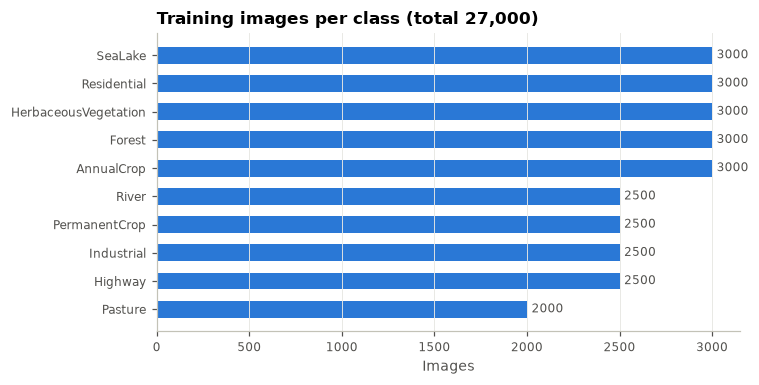

In [4]:
counts = meta["label"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.barh(counts.index, counts.values, color=TRAIN_COLOR, height=0.6)
ax.bar_label(bars, padding=3, fontsize=8, color="#52514e")
ax.set_xlabel("Images")
ax.set_title(f"Training images per class (total {len(meta):,})", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3 · Example images

True-colour composites (B04, B03, B02). Train and test use **the same fixed scaling** (0–2750, as in the
official EuroSAT RGB version), so brightness differences between the datasets are visible directly:
the test images look darker and clearer because atmospheric correction removed the haze.

Training: two random images per class. Test: 20 random images (labels unknown).

In [5]:
def to_rgb(img, vmax=2750):
    """(12, 64, 64) image -> (64, 64, 3) RGB in [0, 1] with fixed scaling."""
    rgb = img[[band_index("B04"), band_index("B03"), band_index("B02")]].astype(np.float32)
    return np.clip(rgb / vmax, 0, 1).transpose(1, 2, 0)

def show_grid(images, titles, suptitle, nrows=5, ncols=4):
    """Show up to nrows * ncols images in a large grid."""
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.6, nrows * 2.85))
    for ax in axes.flat:
        ax.axis("off")
    for ax, img, title in zip(axes.flat, images, titles):
        ax.imshow(to_rgb(img))
        ax.set_title(title, fontsize=9)
    fig.suptitle(suptitle, x=0.02, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()

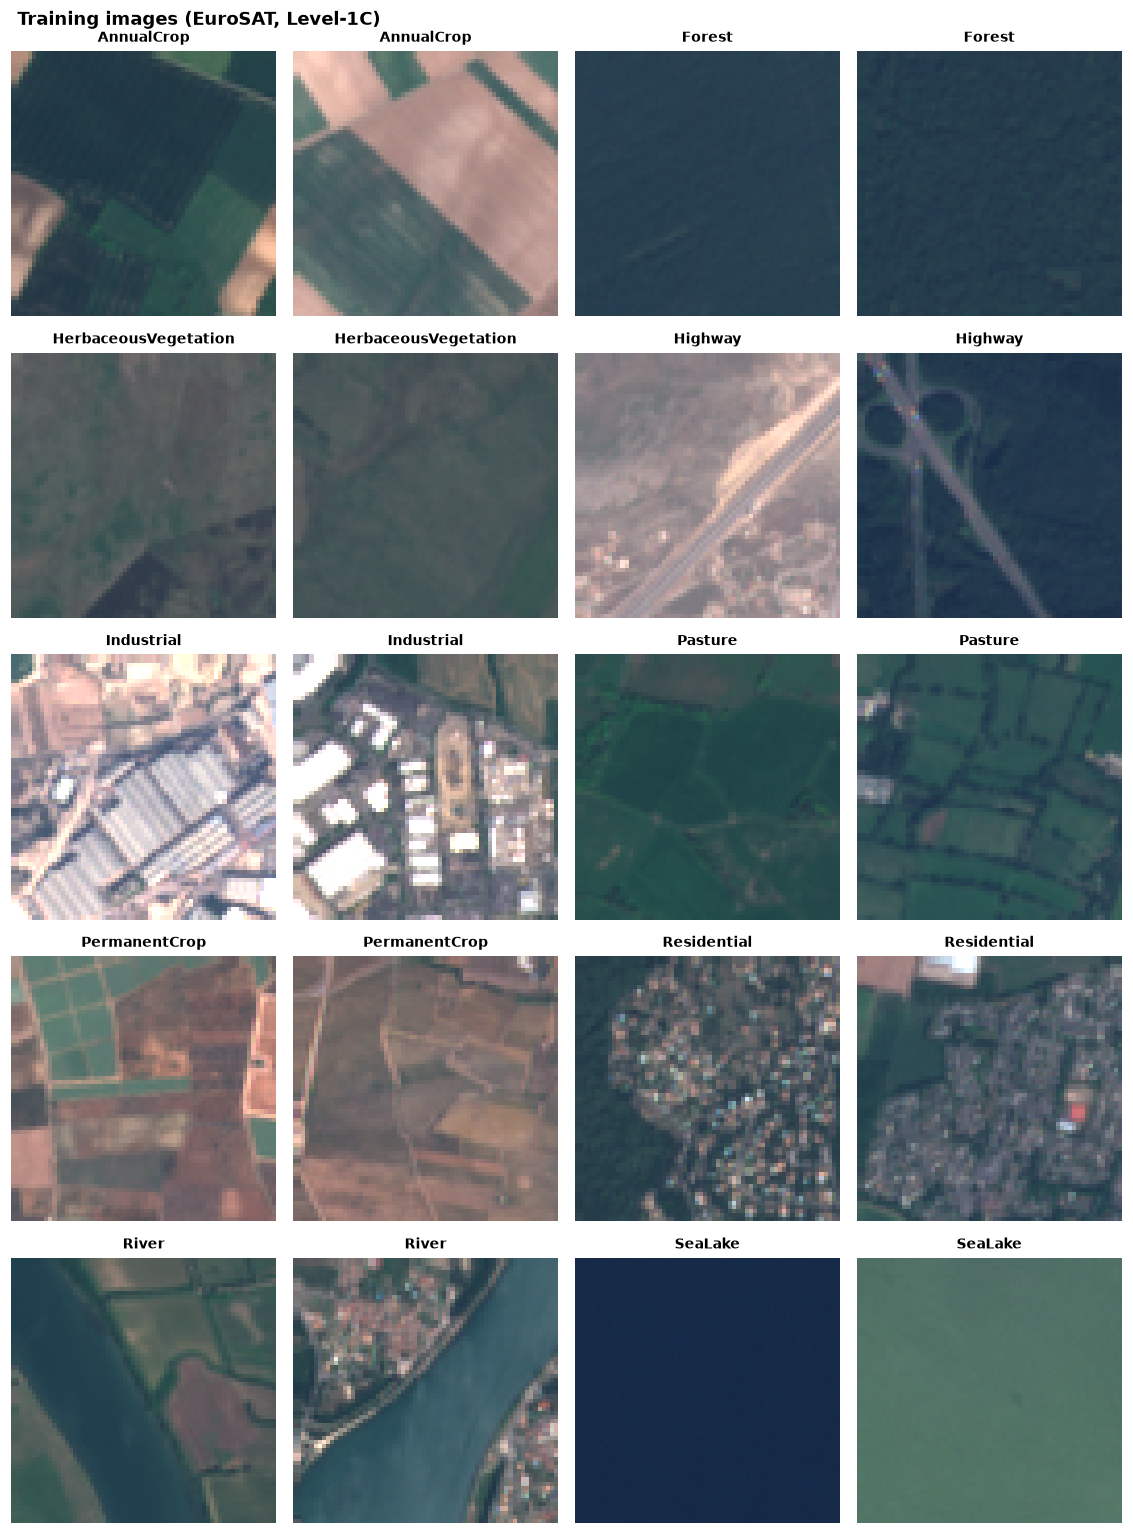

In [6]:
train_idx = [i for cls in CLASSES for i in rng.choice(np.flatnonzero(meta["label"] == cls), 2, replace=False)]
show_grid(X_train[train_idx], meta["label"].values[train_idx], "Training images (EuroSAT, Level-1C)")

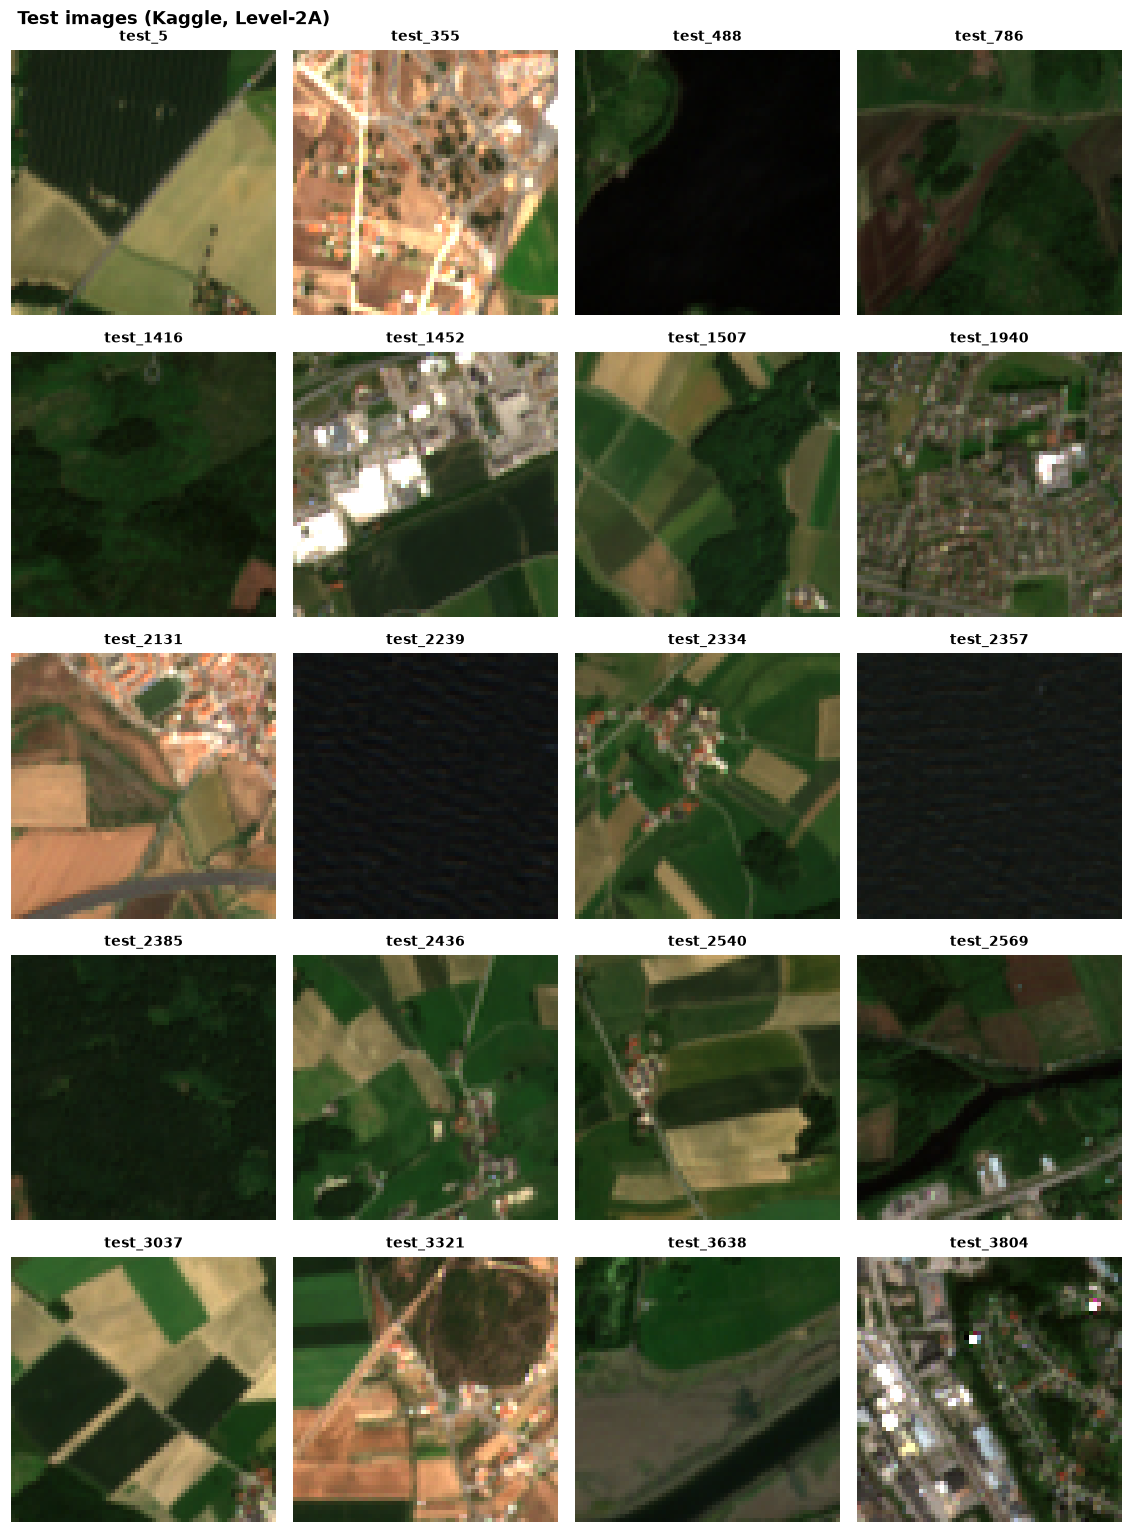

In [7]:
test_idx = np.sort(rng.choice(len(X_test), 20, replace=False))
show_grid(X_test[test_idx], [f"test_{i}" for i in test_ids["test_id"].values[test_idx]], "Test images (Kaggle, Level-2A)")

## 4 · Image size, resolution and value scale

Are the images the same size, do pixels cover the same ground area, and are the values on the same scale?

**Size and format**

In [8]:
import glob
import rasterio

with rasterio.open(sorted(glob.glob(str(EUROSAT_MS_DIR / "Forest" / "*.tif")))[0]) as src:
    tif_info = f"{src.width} x {src.height} px, {src.count} bands, {src.dtypes[0]}, pixel size {src.res[0]:.1f} m"
test_shapes = {np.load(p).shape for p in sorted(TEST_DIR.glob("*.npy"))}
test_dtypes = {str(np.load(p).dtype) for p in sorted(TEST_DIR.glob("*.npy"))[:200]}

pd.DataFrame({
    "Train (EuroSAT GeoTIFF)": [tif_info, "(13, 64, 64): bands first", "yes (CRS + coordinates)"],
    "Test (Kaggle .npy)": [f"shapes found: {test_shapes}, {test_dtypes}", "(64, 64, 12): bands last", "no"],
}, index=["Size and type", "Array layout", "Georeferenced"])

,Train (EuroSAT GeoTIFF),Test (Kaggle .npy)
Size and type,"64 x 64 px, 13 bands, uint16, pixel size 10.0 m","shapes found: {(64, 64, 12)}, {'uint16'}"
Array layout,"(13, 64, 64): bands first","(64, 64, 12): bands last"
Georeferenced,yes (CRS + coordinates),no


**Resolution.** Sentinel-2 records bands at 10, 20 or 60 m. In both datasets, all bands were
enlarged to 10 m pixels so every band is 64 × 64 (= 640 m × 640 m). Two measurements per band:

- **Smoothness**: correlation between neighbouring pixels. Equal values for the 10 m bands mean the pixels cover the same ground area.
- **2-pixel pattern**: how much neighbouring pixels differ *inside* the original 20 m pixels compared to *across* their edges. 1.0 means no pattern; lower values mean the original 20 m grid is still visible. (EuroSAT sits at 0.97 in every band, including the 10 m ones, which looks like a very weak artefact of its own processing; what matters is the much lower test value for the 20 m bands.)

In [9]:
NATIVE_RES = {"B01": 60, "B02": 10, "B03": 10, "B04": 10, "B05": 20, "B06": 20, "B07": 20,
              "B08": 10, "B8A": 20, "B09": 60, "B11": 20, "B12": 20}

def neighbour_corr(x):
    """Mean correlation between horizontally neighbouring pixels, per band."""
    z = (x - x.mean(axis=(2, 3), keepdims=True)) / (x.std(axis=(2, 3), keepdims=True) + 1e-6)
    return (z[..., 1:] * z[..., :-1]).mean(axis=(0, 2, 3))

def grid_pattern(x):
    """Mean |difference| inside 2-pixel blocks divided by across block edges, per band."""
    d = np.abs(np.diff(x, axis=3))
    return d[..., 0::2].mean(axis=(0, 2, 3)) / (d[..., 1::2].mean(axis=(0, 2, 3)) + 1e-6)

resolution = pd.DataFrame({
    "native resolution (m)": [NATIVE_RES[b] for b in TEST_BANDS],
    "smoothness train": neighbour_corr(train_sample),
    "smoothness test": neighbour_corr(test_sample),
    "2-px pattern train": grid_pattern(train_sample),
    "2-px pattern test": grid_pattern(test_sample),
}, index=TEST_BANDS).round(3)
resolution

,native resolution (m),smoothness train,smoothness test,2-px pattern train,2-px pattern test
B01,60,0.985,0.983,0.969,0.936
B02,10,0.788,0.803,0.969,0.999
B03,10,0.813,0.818,0.969,0.999
B04,10,0.826,0.832,0.969,1.000
B05,20,0.963,0.938,0.969,0.786
B06,20,0.964,0.936,0.968,0.785
B07,20,0.964,0.936,0.968,0.788
B08,10,0.853,0.836,0.968,0.999
B8A,20,0.965,0.937,0.968,0.799
B09,60,0.985,0.984,0.968,0.940


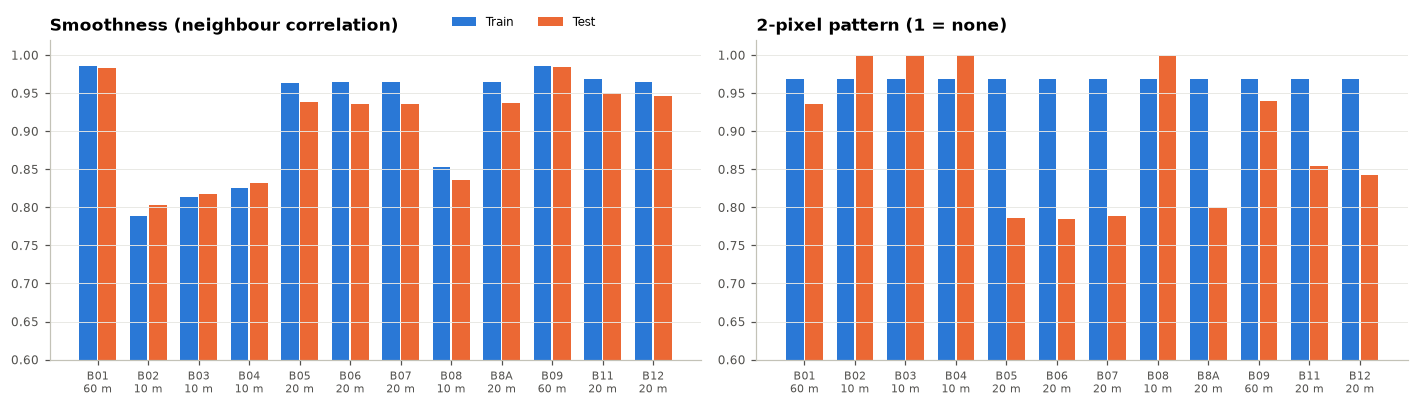

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
x = np.arange(12)
w = 0.38
for ax, col, title in [(axes[0], "smoothness", "Smoothness (neighbour correlation)"),
                       (axes[1], "2-px pattern", "2-pixel pattern (1 = none)")]:
    ax.bar(x - w / 2, resolution[f"{col} train"], w - 0.03, color=TRAIN_COLOR, label="Train")
    ax.bar(x + w / 2, resolution[f"{col} test"], w - 0.03, color=TEST_COLOR, label="Test")
    ax.set_xticks(x, [f"{b}\n{NATIVE_RES[b]} m" for b in TEST_BANDS], fontsize=7)
    ax.set_title(title, loc="left")
    ax.set_ylim(0.6, 1.02)
    ax.grid(axis="x", visible=False)
axes[0].legend(ncol=2, loc="lower left", bbox_to_anchor=(0.6, 1.0))
plt.tight_layout()
plt.show()

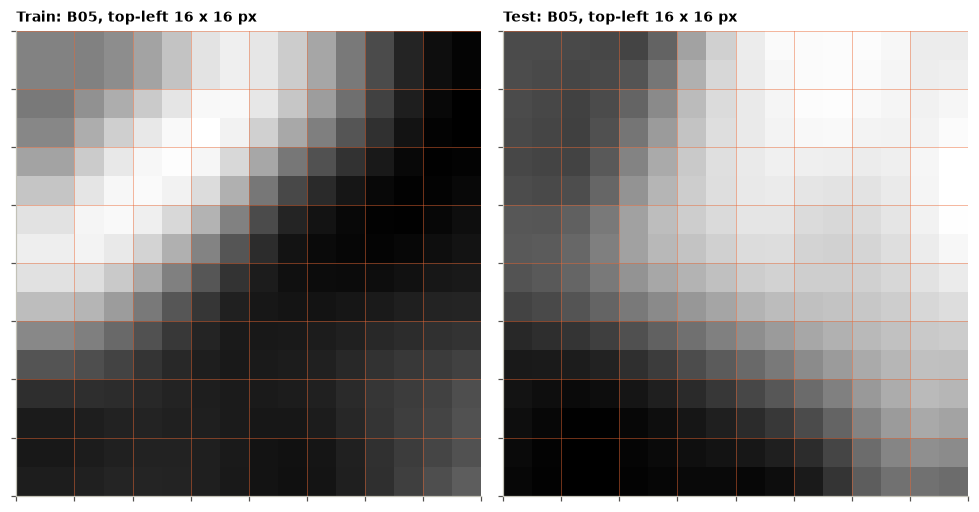

In [11]:
# Zoom: one 20 m band (B05), 16 x 16 px, of the most detailed example image in each dataset.
# Grid lines mark the original 20 m pixels (2 x 2 px). Displayed without smoothing.
b = band_index("B05")
best_train = train_idx[np.argmax([X_train[i, b, :16, :16].std() for i in train_idx])]
best_test = test_idx[np.argmax([X_test[i, b, :16, :16].std() for i in test_idx])]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, img, title in [(axes[0], X_train[best_train], "Train: B05, top-left 16 x 16 px"),
                       (axes[1], X_test[best_test], "Test: B05, top-left 16 x 16 px")]:
    ax.imshow(img[b, :16, :16], cmap="gray", interpolation="nearest")
    ax.set_title(title, loc="left", fontsize=9)
    ax.set_xticks(np.arange(-0.5, 16, 2), [])
    ax.set_yticks(np.arange(-0.5, 16, 2), [])
    ax.grid(True, color="#eb6834", lw=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

**Value scale.** Both datasets store reflectance × 10,000 as `uint16` (10,000 = 100% reflectance).
Newer Level-2A products can add an offset of +1,000 to every value; if the test set had it, its
lowest values would be around 1,000.

In [12]:
scale = pd.DataFrame({
    "train": np.percentile(train_sample, [0.1, 1, 50, 99, 99.9]),
    "test": np.percentile(test_sample, [0.1, 1, 50, 99, 99.9]),
}, index=["0.1th percentile", "1st percentile", "median", "99th percentile", "99.9th percentile"]).round(0)
scale

,train,test
0.1th percentile,11.0,25.0
1st percentile,38.0,107.0
median,1306.0,837.0
99th percentile,4429.0,4879.0
99.9th percentile,5509.0,5962.0


**Findings**

| Question | Answer |
|---|---|
| Same image size? | **Yes.** 64 × 64 pixels, every band, both datasets. Only the array layout differs (bands first vs bands last). |
| Same ground resolution? | **Yes.** 10 m per pixel: the 10 m bands (B02, B03, B04, B08) have the same smoothness in both datasets. |
| Same enlargement of the 20 m and 60 m bands? | **No.** In the test set, the 20 m bands still show the original 2-pixel grid (pattern ≈ 0.8 vs 0.97 in training) and are a bit less smooth. EuroSAT used a smooth interpolation (cubic spline, according to the paper); the test set looks like a simpler method such as bilinear interpolation. A small difference, but a CNN can pick up on texture like this. |
| Same value scale? | **Yes.** Reflectance × 10,000 in both, and no +1,000 offset in the test set (lowest values near 0). The *values* differ because of the atmospheric correction (section 6), not because of a different scale. |

**Consequence:** the different enlargement can be imitated in preprocessing or augmentation: shrink the
training 20 m bands to 32 × 32 and enlarge them again the way the test set did. This would be one
experiment in `04_preprocessing.ipynb`.

## 5 · Band order check

The two datasets store bands in different orders:

| Position | 1–8 | 9 | 10 | 11 | 12 | 13 |
|---|---|---|---|---|---|---|
| EuroSAT GeoTIFF | B01–B08 | B09 | B10 | B11 | B12 | B8A |
| Kaggle .npy | B01–B08 | **B8A** | **B09** | B11 | B12 | – |

Brightness alone can't confirm the mapping, because atmospheric correction changes it. But the
**correlation between bands** is a fingerprint that survives the correction: e.g. B08 and B8A are
almost identical. If the mapping is right, the two correlation matrices should look alike.

Mean |difference| with our mapping:   0.091
Mean |difference| with naive mapping: 0.188


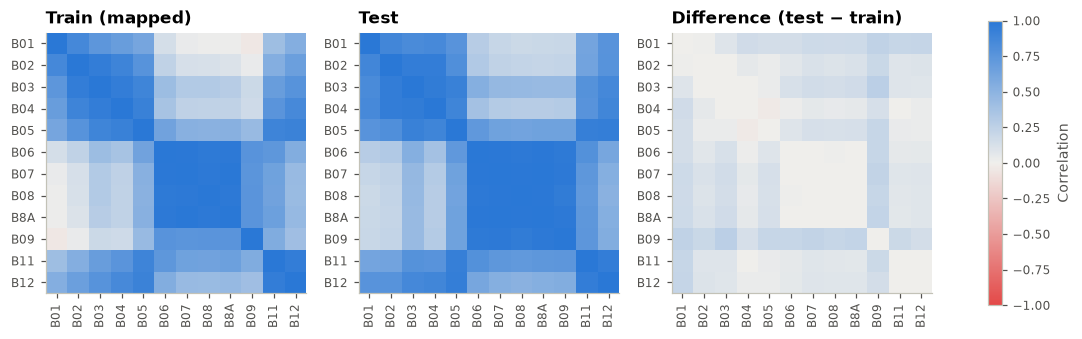

In [13]:
def band_corr(x):
    """12x12 pixel-level correlation between bands."""
    return np.corrcoef(x.transpose(1, 0, 2, 3).reshape(12, -1))

corr_train, corr_test = band_corr(train_sample[::4]), band_corr(test_sample[::4])  # every 4th image: all classes

# Wrong mapping for comparison: test bands read in the original EuroSAT order (without B10)
naive = [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 8]
corr_train_naive = corr_train[np.ix_(naive, naive)]
print(f"Mean |difference| with our mapping:   {np.abs(corr_train - corr_test).mean():.3f}")
print(f"Mean |difference| with naive mapping: {np.abs(corr_train_naive - corr_test).mean():.3f}")

diverging = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, m, title in zip(axes,
                        [corr_train, corr_test, corr_test - corr_train],
                        ["Train (mapped)", "Test", "Difference (test − train)"]):
    im = ax.imshow(m, cmap=diverging, vmin=-1, vmax=1)
    ax.set_xticks(range(12), TEST_BANDS, rotation=90)
    ax.set_yticks(range(12), TEST_BANDS)
    ax.set_title(title, loc="left")
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="Correlation")
plt.show()

## 6 · Brightness per band: train vs test

Mean value per band over **all** images. The ratio test ÷ train shows the effect of atmospheric
correction: haze scatters short wavelengths most, so removing it darkens the blue end of the
spectrum much more than the infrared end.

In [14]:
mean_train = X_train.mean(axis=(0, 2, 3), dtype=np.float64)
mean_test = X_test.mean(axis=(0, 2, 3), dtype=np.float64)
std_train = train_sample.std(axis=(0, 2, 3))
std_test = test_sample.std(axis=(0, 2, 3))

band_stats = pd.DataFrame({
    "wavelength_nm": [WAVELENGTH_NM[b] for b in TEST_BANDS],
    "train_mean": mean_train, "test_mean": mean_test,
    "ratio_test/train": mean_test / mean_train,
    "train_std": std_train, "test_std": std_test,
}, index=TEST_BANDS).round(2)
band_stats

,wavelength_nm,train_mean,test_mean,ratio_test/train,train_std,test_std
B01,443,1353.73,380.17,0.28,245.289993,311.519989
B02,490,1117.20,400.15,0.36,331.429993,406.190002
B03,560,1041.88,628.86,0.60,395.290009,486.029999
B04,665,946.55,578.87,0.61,599.880005,598.099976
B05,705,1199.19,943.43,0.79,576.690002,659.500000
B06,740,2003.01,1826.24,0.91,878.419983,1181.579956
B07,783,2374.01,2116.67,0.89,1106.739990,1419.180054
B08,842,2301.22,2205.97,0.96,1139.520020,1506.420044
B8A,865,2599.78,2281.19,0.88,1255.650024,1522.109985
B09,945,732.18,2266.93,3.10,414.489990,1472.819946


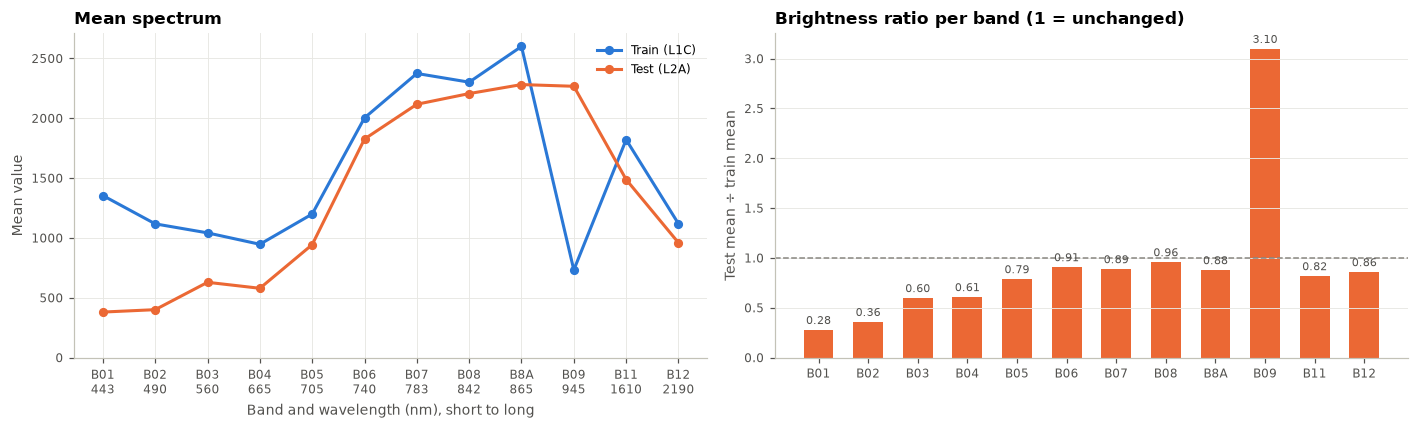

In [15]:
order = np.argsort(band_stats["wavelength_nm"].values)
wl = band_stats["wavelength_nm"].values[order]
names = np.array(TEST_BANDS)[order]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
pos = np.arange(12)
ax.plot(pos, mean_train[order], "-o", color=TRAIN_COLOR, ms=5, label="Train (L1C)")
ax.plot(pos, mean_test[order], "-o", color=TEST_COLOR, ms=5, label="Test (L2A)")
ax.set_xticks(pos, [f"{n}\n{w}" for n, w in zip(names, wl)])
ax.set_xlabel("Band and wavelength (nm), short to long")
ax.set_ylabel("Mean value")
ax.set_title("Mean spectrum", loc="left")
ax.set_ylim(bottom=0)
ax.legend()

ax = axes[1]
ratio = band_stats["ratio_test/train"].values[order]
bars = ax.bar(names, ratio, color=TEST_COLOR, width=0.6)
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=7, color="#52514e")
ax.set_ylabel("Test mean ÷ train mean")
ax.set_title("Brightness ratio per band (1 = unchanged)", loc="left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 7 · Pixel distributions per band

Histograms of pixel values (3,000 random images per dataset). Shifts in the location *and*
the width of the distributions matter: a simple scaling can't fix both if they move differently.

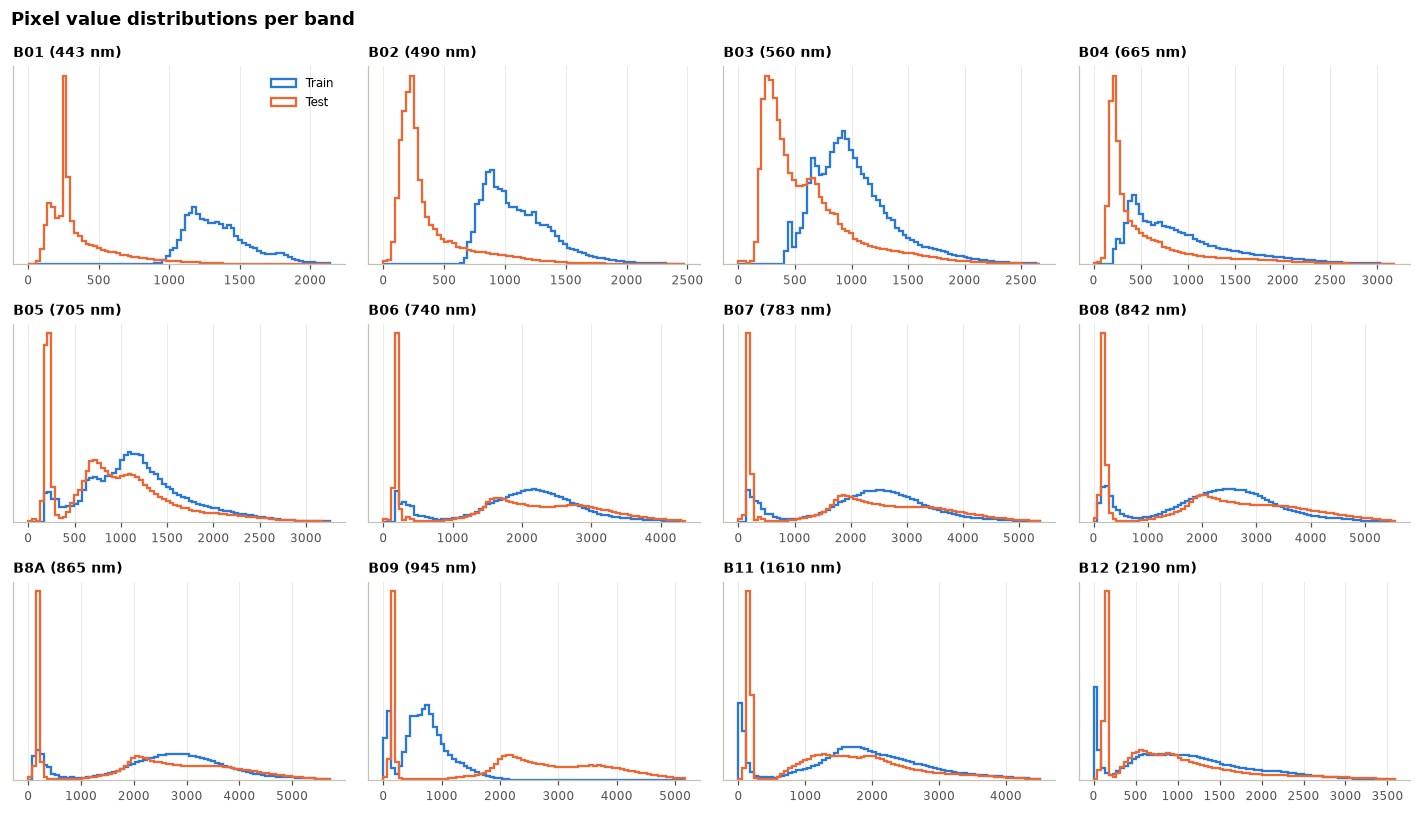

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(13, 7.5), sharey=False)
for i, ax in enumerate(axes.flat):
    a, b = train_sample[:, i].ravel(), test_sample[:, i].ravel()
    hi = np.percentile(np.concatenate([a[::50], b[::50]]), 99.5)
    bins = np.linspace(0, hi, 80)
    ax.hist(a, bins=bins, density=True, histtype="step", color=TRAIN_COLOR, lw=1.5, label="Train")
    ax.hist(b, bins=bins, density=True, histtype="step", color=TEST_COLOR, lw=1.5, label="Test")
    ax.set_title(f"{TEST_BANDS[i]} ({WAVELENGTH_NM[TEST_BANDS[i]]} nm)", loc="left", fontsize=9)
    ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle("Pixel value distributions per band", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 8 · Spectral signature per class

Mean spectrum of each class in the training data. Classes that look alike here (e.g. the vegetation
classes) must be told apart by texture and shape, which is what a CNN adds over per-pixel features.

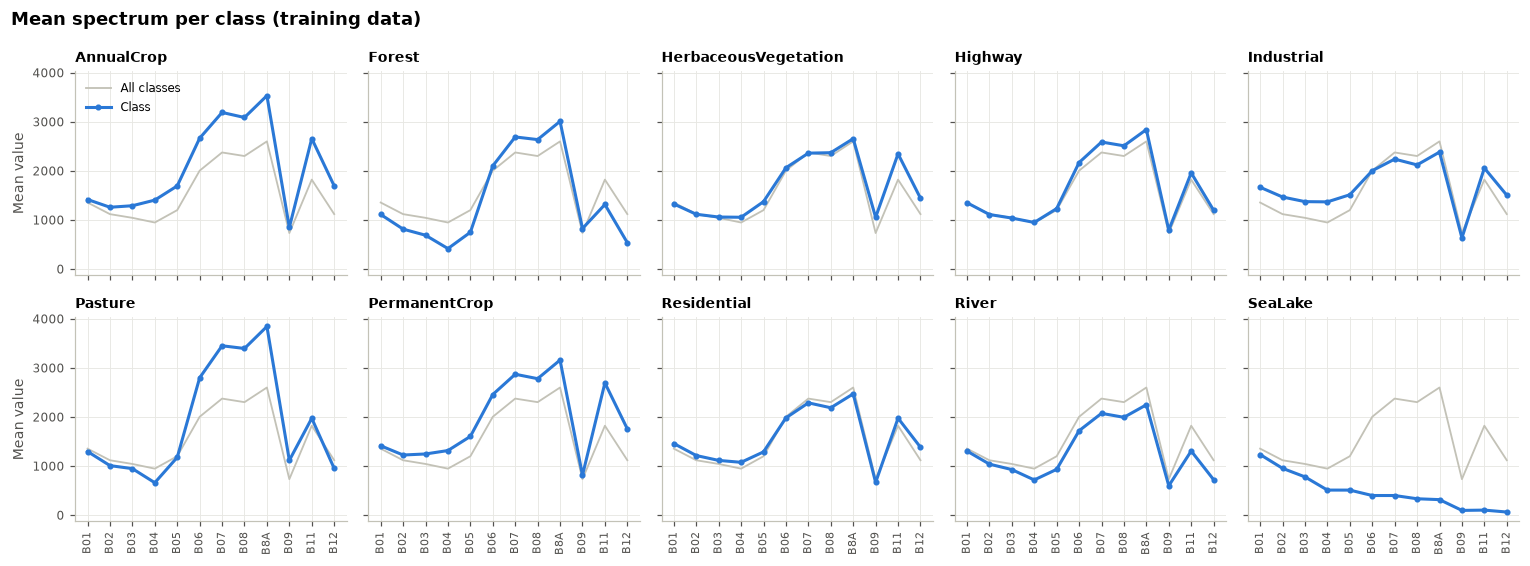

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5.2), sharex=True, sharey=True)
for ax, (cls_id, cls) in zip(axes.flat, enumerate(CLASSES)):
    idx = np.flatnonzero(meta["label_id"].values == cls_id)
    spec = X_train[idx].mean(axis=(0, 2, 3), dtype=np.float64)
    ax.plot(pos, mean_train[order], color="#c3c2b7", lw=1.2, label="All classes")
    ax.plot(pos, spec[order], "-o", color=TRAIN_COLOR, ms=3, label=cls)
    ax.set_xticks(pos, names, rotation=90, fontsize=7)
    ax.set_title(cls, loc="left", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("Mean value")
axes[0, 0].legend(["All classes", "Class"], loc="upper left")
fig.suptitle("Mean spectrum per class (training data)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 9 · Spectral indices

Normalised differences of two bands. Because they are ratios, they are partly insensitive to
brightness changes, which makes them candidates for extra input channels.

- **NDVI** = (B08 − B04) / (B08 + B04): vegetation
- **NDWI** = (B03 − B08) / (B03 + B08): open water

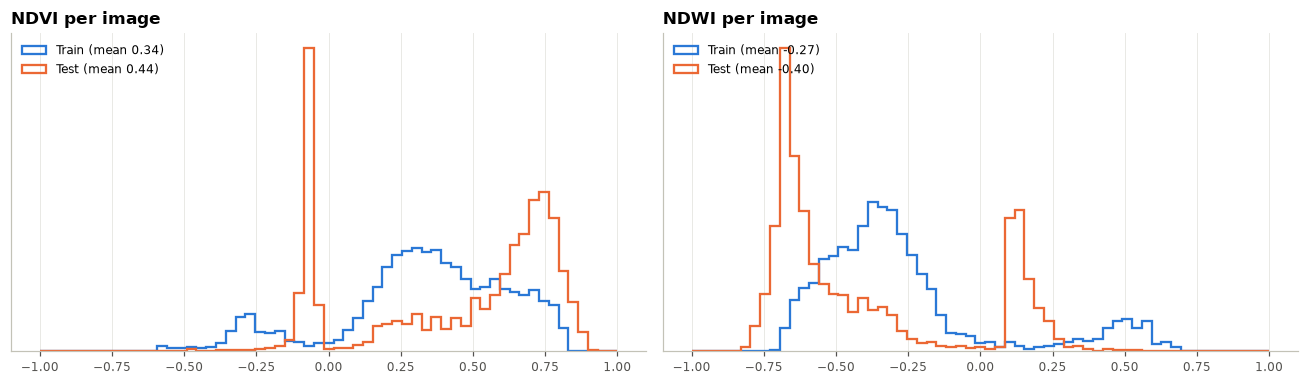

In [18]:
def norm_diff(x, a, b):
    """Per-image mean of (a - b) / (a + b)."""
    A, B = x[:, band_index(a)], x[:, band_index(b)]
    return ((A - B) / (A + B + 1e-6)).mean(axis=(1, 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, (name, a, b) in zip(axes, [("NDVI", "B08", "B04"), ("NDWI", "B03", "B08")]):
    tr, te = norm_diff(train_sample, a, b), norm_diff(test_sample, a, b)
    bins = np.linspace(-1, 1, 60)
    ax.hist(tr, bins=bins, density=True, histtype="step", lw=1.5, color=TRAIN_COLOR, label=f"Train (mean {tr.mean():.2f})")
    ax.hist(te, bins=bins, density=True, histtype="step", lw=1.5, color=TEST_COLOR, label=f"Test (mean {te.mean():.2f})")
    ax.set_title(f"{name} per image", loc="left")
    ax.set_yticks([])
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 10 · Data quality

Value ranges, empty or saturated pixels, and exact duplicate images.

In [19]:
def quality(x):
    flat = x.reshape(len(x), -1)
    return {
        "images": len(x),
        "min": int(x.min()),
        "max": int(x.max()),
        "images with zero pixels": int((flat == 0).any(axis=1).sum()),
        "images with pixels >= 10000": int((flat >= 10000).any(axis=1).sum()),
        "possible duplicate images": int(len(x) - len(np.unique([hash(img.tobytes()) for img in x]))),
    }

pd.DataFrame({"train": quality(np.asarray(X_train)), "test": quality(np.asarray(X_test))})

,train,test
images,27000,4232
min,0,0
max,28003,20506
images with zero pixels,7,1
images with pixels >= 10000,391,60
possible duplicate images,0,0


## 11 · Geography and neighbouring patches

Every EuroSAT GeoTIFF carries coordinates. Each patch covers 640 × 640 m, so two patches whose
centres are less than ~700 m apart touch or overlap. If neighbouring patches land in both the
internal train and internal test split, the internal test score is inflated. This is checked
again in `03_split.ipynb`.

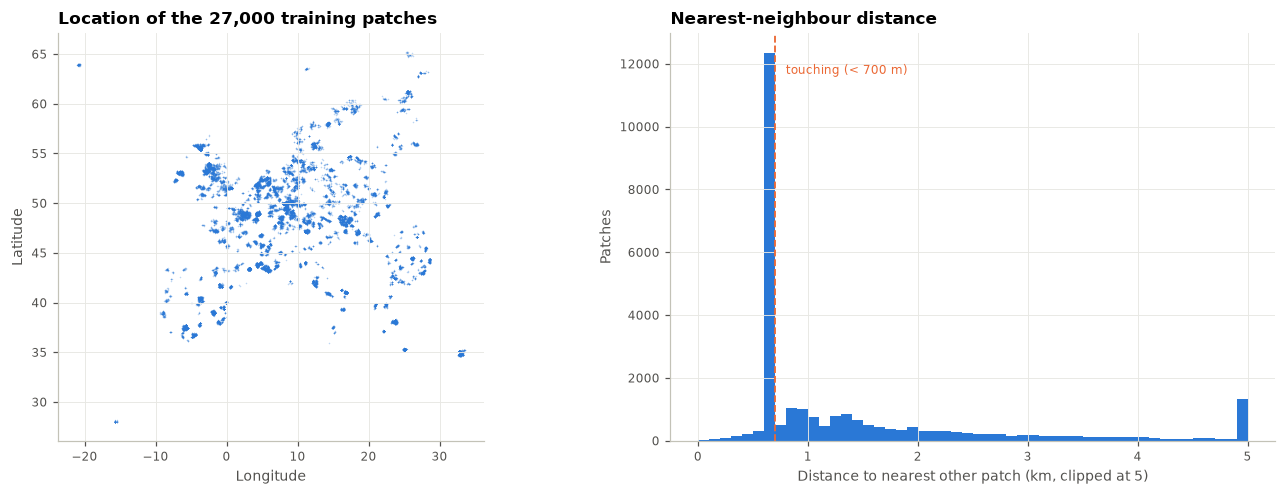

Patches with a touching neighbour: 13,179 (48.8%)
  of which the neighbour has the same class: 97.9%
Median nearest-neighbour distance: 0.8 km


In [20]:
from scipy.spatial import cKDTree

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.scatter(meta["lon"], meta["lat"], s=1, color=TRAIN_COLOR, alpha=0.3, linewidths=0)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Location of the 27,000 training patches", loc="left")
ax.set_aspect(1.4)

# Approximate metres (fine at this scale) and nearest-neighbour distances
lat0 = np.deg2rad(meta["lat"].mean())
xy = np.c_[meta["lon"] * 111_320 * np.cos(np.deg2rad(meta["lat"])), meta["lat"] * 110_574]
dist, nn = cKDTree(xy).query(xy, k=2)
nn_dist, nn_idx = dist[:, 1], nn[:, 1]
touching = nn_dist < 700
same_class = meta["label_id"].values == meta["label_id"].values[nn_idx]

ax = axes[1]
ax.hist(np.clip(nn_dist / 1000, 0, 5), bins=np.arange(0, 5.1, 0.1), color=TRAIN_COLOR)
ax.axvline(0.7, color=TEST_COLOR, ls="--", lw=1.2)
ax.text(0.8, ax.get_ylim()[1] * 0.9, "touching (< 700 m)", color=TEST_COLOR, fontsize=8)
ax.set_xlabel("Distance to nearest other patch (km, clipped at 5)")
ax.set_ylabel("Patches")
ax.set_title("Nearest-neighbour distance", loc="left")
plt.tight_layout()
plt.show()

print(f"Patches with a touching neighbour: {touching.sum():,} ({touching.mean():.1%})")
print(f"  of which the neighbour has the same class: {same_class[touching].mean():.1%}")
print(f"Median nearest-neighbour distance: {np.median(nn_dist) / 1000:.1f} km")

## 12 · Summary

In [21]:
# Share of very dark (water-like) images: mean NIR (B08) below 500
nir_train = X_train[:, band_index("B08")].mean(axis=(1, 2))
nir_test = X_test[:, band_index("B08")].mean(axis=(1, 2))
dark_train, dark_test = nir_train < 500, nir_test < 500
print(f"Dark images: train {dark_train.mean():.1%}, test {dark_test.mean():.1%}")
print("Classes of the dark training images:", meta.loc[dark_train, "label"].value_counts().to_dict())

Dark images: train 9.1%, test 23.5%
Classes of the dark training images: {'SeaLake': 2462, 'River': 1}


| # | Finding | Consequence |
|---|---|---|
| 1 | **Band order differs** between EuroSAT and the test set. The correlation fingerprint confirms the mapping in `src/data.py` (difference 0.09 vs 0.19 for the naive order). | Always load data through `src/data.py`. |
| 2 | **Atmospheric correction darkens short wavelengths most**: test ÷ train is 0.28 for B01, 0.36 for B02, ~0.6 for green/red, 0.8–0.96 for red edge, NIR and SWIR. | Per-band (not global) harmonization and per-band brightness augmentation. |
| 3 | **B09 is not comparable**: 3.1× brighter in the test set, with a different distribution shape. | Drop B09 (or test with and without it). |
| 4 | **The test set has about twice as much water**: 23.5% of test images are very dark in NIR vs 9.1% in training, and in training all of those are SeaLake. | The test class mix is not balanced like EuroSAT. Statistics computed over the whole test set (e.g. for harmonization) are pulled towards water. |
| 5 | **Spectral indices shift too** (mean NDVI 0.34 → 0.44), partly from the correction and partly from the different class mix. | Indices help but don't remove the shift. |
| 6 | **Data is clean**: no duplicates, 7 train images with zero pixels, 391 with very bright pixels (≥ 10,000, e.g. clouds or snow). | Clip extreme values when normalising. |
| 7 | **The 20 m bands were enlarged differently**: the test set still shows the original 2-pixel grid, EuroSAT is smoother. Image size (64 × 64), ground resolution (10 m) and value scale (reflectance × 10,000, no offset) are the same. | Optionally imitate the test set's enlargement for the training 20 m bands. |
| 8 | **Half of all patches (48.8%) touch a neighbouring patch, and 97.9% of those neighbours have the same class.** | A random split puts neighbours into both internal train and test, which inflates the internal score. `03_split.ipynb` groups neighbouring patches so they stay in the same split. |